In [ ]:
# %% CELL 1 — Install dependencies
!pip install pytorch-lightning shap lime --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 15.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 67.9 MB/s eta 0:00:00


In [ ]:
# %% CELL 2 — Imports
# -----------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
matplotlib.rcParams.update({"figure.dpi": 120, "font.size": 10})

# ── Mounting Drive and adding project root to path ──────────────────────────────────
from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = "/content/drive/MyDrive/MP2"
sys.path.insert(0, PROJECT_ROOT)

import shap
from lime.lime_tabular import LimeTabularExplainer

from src.data_load.dataset import ICUDataset
from src.models.multimodal_model import MultimodalICUModel

print("✓ All imports successful")

Mounted at /content/drive
✓ All imports successful


In [ ]:
# %% CELL 3 — Paths and constants
# -----------------------------------------------------------------------------
CKPT_PATH   = f"{PROJECT_ROOT}/outputs/checkpoints/best_calibrated.ckpt"
PKL_PATH    = f"{PROJECT_ROOT}/data/new2.pkl"
FIG_DIR     = f"{PROJECT_ROOT}/outputs/figures"
os.makedirs(FIG_DIR, exist_ok=True)

VITALS_DIM      = 24 * 5   # 120  (flattened)
TABULAR_DIM     = 156
FLAT_DIM        = VITALS_DIM + TABULAR_DIM   # 276
DEVICE          = torch.device("cpu")
VITAL_CHANNELS  = ["HR", "RR", "SBP", "DBP", "SpO2"]

print(f"Flat input dim : {FLAT_DIM}  ({VITALS_DIM} vitals + {TABULAR_DIM} tabular)")
print(f"Figures → {FIG_DIR}")

Flat input dim : 276  (120 vitals + 156 tabular)
Figures → /content/drive/MyDrive/MP2/outputs/figures


In [ ]:
# %% CELL 4 — Load model
# -----------------------------------------------------------------------------
# Load model weights
state = torch.load("/content/drive/MyDrive/MP2/outputs/checkpoints/best_calibrated.ckpt", map_location=DEVICE)
model = MultimodalICUModel(config={})
model.load_state_dict(state, strict=False)

# Load calibration artifacts
artifacts = torch.load("/content/drive/MyDrive/MP2/outputs/checkpoints/calibration_artifacts.pt", map_location=DEVICE)
model.band2_threshold    = artifacts["band2_threshold"]
model.mortality_threshold = artifacts["mortality_threshold"]
# Temperatures are for Platt scaling — store separately if needed
b1_temp   = artifacts["b1_temperature"]
mort_temp = artifacts["mort_temperature"]

model.eval()
print(f"✓ Model loaded")
print(f"   band2_threshold    : {model.band2_threshold:.6f}")
print(f"   mortality_threshold: {model.mortality_threshold:.6f}")

✓ Model loaded
   band2_threshold    : 0.469675
   mortality_threshold: 0.188724


In [ ]:
# %% CELL 5 — Load datasets
# -----------------------------------------------------------------------------
train_ds = ICUDataset(PKL_PATH, split="train")
test_ds  = ICUDataset(PKL_PATH, split="test")

# Raw numpy arrays
vitals_train  = train_ds.vitals.numpy()          # (N_train, 24, 5)
tabular_train = train_ds.tabular.numpy()          # (N_train, 156)
los_train     = train_ds.los_labels.numpy()       # (N_train,)

vitals_test   = test_ds.vitals.numpy()
tabular_test  = test_ds.tabular.numpy()
los_test      = test_ds.los_labels.numpy()
mort_test     = test_ds.mortality_labels.numpy().astype(int)

feature_names_tabular = test_ds.feature_names     # list[str], length 156
assert feature_names_tabular is not None, \
    "feature_names is None — regenerate pickle with feature_names key"
assert len(feature_names_tabular) == TABULAR_DIM, \
    f"Expected {TABULAR_DIM} feature names, got {len(feature_names_tabular)}"

print(f"Train : {len(train_ds):,}")
print(f"Test  : {len(test_ds):,}")
print(f"LOS band counts (test) : { {b: int((los_test==b).sum()) for b in [0,1,2]} }")
print(f"Mortality count (test) : died={int(mort_test.sum())}  survived={int((mort_test==0).sum())}")

Train : 10,500
Test  : 2,250
LOS band counts (test) : {0: 453, 1: 964, 2: 833}
Mortality count (test) : died=233  survived=2017


In [ ]:
# %% CELL 6 — Flat arrays and feature names
# -----------------------------------------------------------------------------

def build_flat_input(vitals_np: np.ndarray, tabular_np: np.ndarray) -> np.ndarray:
    """
    vitals_np  : (N, 24, 5)
    tabular_np : (N, 156)
    → (N, 276)  [vitals flattened row-major then tabular concatenated]
    """
    vitals_flat = vitals_np.reshape(len(vitals_np), -1)          # (N, 120)
    return np.concatenate([vitals_flat, tabular_np], axis=1).astype(np.float32)


def make_all_feature_names(tabular_names):
    """
    Returns the 276-dim name list matching build_flat_input column order.
    Vitals: vital_h{hour}_{channel}  e.g. vital_h00_HR, vital_h00_RR ...
    Then the 156 tabular names unchanged.
    """
    vital_names = [
        f"vital_h{h:02d}_{ch}"
        for h in range(24)
        for ch in VITAL_CHANNELS
    ]
    return vital_names + list(tabular_names)


all_feature_names = make_all_feature_names(feature_names_tabular)

X_train_flat = build_flat_input(vitals_train, tabular_train)    # (N_train, 276)
X_test_flat  = build_flat_input(vitals_test,  tabular_test)     # (N_test,  276)

print(f"X_train_flat : {X_train_flat.shape}")
print(f"X_test_flat  : {X_test_flat.shape}")
print(f"Feature names: {len(all_feature_names)}  (first 3: {all_feature_names[:3]})")

X_train_flat : (10500, 276)
X_test_flat  : (2250, 276)
Feature names: 276  (first 3: ['vital_h00_HR', 'vital_h00_RR', 'vital_h00_SBP'])


In [ ]:
# %% CELL 7 — predict_fn wrapper + smoke test
# -----------------------------------------------------------------------------
def make_predict_fn(model, head: str = "los"):
    """
    Returns predict_fn(X: np.ndarray[N, 276]) → np.ndarray[N, n_classes]

    head="los"       → (N, 3) band probabilities [Band0, Band1, Band2]
    head="mortality" → (N, 2) probabilities [P(survive), P(die)]
    """
    model.eval()

    def predict_fn(X: np.ndarray) -> np.ndarray:
        X_t     = torch.tensor(X, dtype=torch.float32).to(DEVICE)
        vitals  = X_t[:, :VITALS_DIM].reshape(-1, 24, 5)
        tabular = X_t[:, VITALS_DIM:]

        with torch.no_grad():
            los_logits, mort_logit = model(vitals, tabular)

            if head == "los":
                # Ordinal threshold logits → band probabilities
                p1    = torch.sigmoid(los_logits[:, 0])          # P(LOS >= Band1)
                p2    = torch.sigmoid(los_logits[:, 1])          # P(LOS >= Band2)
                band0 = 1.0 - p1
                band1 = torch.clamp(p1 - p2, min=0.0)            # clamp prevents negatives
                band2 = p2
                probs = torch.stack([band0, band1, band2], dim=1) # (N, 3)
                return probs.cpu().numpy()

            else:  # mortality
                p    = torch.sigmoid(mort_logit).squeeze(1)       # (N,)
                probs = torch.stack([1.0 - p, p], dim=1)          # (N, 2)
                return probs.cpu().numpy()

    return predict_fn


predict_fn_los  = make_predict_fn(model, head="los")
predict_fn_mort = make_predict_fn(model, head="mortality")

# Smoke test
_s = X_test_flat[:4]
_o_los  = predict_fn_los(_s)
_o_mort = predict_fn_mort(_s)
assert _o_los.shape  == (4, 3), f"Bad LOS shape: {_o_los.shape}"
assert _o_mort.shape == (4, 2), f"Bad Mort shape: {_o_mort.shape}"
assert np.allclose(_o_los.sum(axis=1),  1.0, atol=1e-4), "LOS probs don't sum to 1"
assert np.allclose(_o_mort.sum(axis=1), 1.0, atol=1e-4), "Mort probs don't sum to 1"
print("✓ predict_fn smoke test passed")
print(f"  Sample LOS  probs: {_o_los.round(3)}")
print(f"  Sample Mort probs: {_o_mort.round(3)}")

✓ predict_fn smoke test passed
  Sample LOS  probs: [[0.496 0.007 0.497]
 [0.267 0.284 0.45 ]
 [0.541 0.079 0.38 ]
 [0.452 0.021 0.526]]
  Sample Mort probs: [[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]


In [ ]:
# %% CELL 8 — SHAP wrapper modules + GradientExplainer setup
# -----------------------------------------------------------------------------

class LOSWrapper(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, X):
        v = X[:, :VITALS_DIM].reshape(-1, 24, 5)
        t = X[:, VITALS_DIM:]
        los_logits, _ = self.m(v, t)
        return los_logits

class MortWrapper(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, X):
        v = X[:, :VITALS_DIM].reshape(-1, 24, 5)
        t = X[:, VITALS_DIM:]
        _, mort_logit = self.m(v, t)
        return mort_logit

los_wrapper  = LOSWrapper(model).eval()
mort_wrapper = MortWrapper(model).eval()


def stratified_sample_idx(labels: np.ndarray, n_per_class: int, seed: int = 42):
    rng = np.random.default_rng(seed)
    out = []
    for cls in np.unique(labels):
        pool   = np.where(labels == cls)[0]
        chosen = rng.choice(pool, size=min(n_per_class, len(pool)), replace=False)
        out.extend(chosen.tolist())
    return np.array(out)


bg_idx       = stratified_sample_idx(los_train, n_per_class=70)
background_t = torch.tensor(X_train_flat[bg_idx], dtype=torch.float32)

shap_explainer_los  = shap.GradientExplainer(los_wrapper,  background_t)
shap_explainer_mort = shap.GradientExplainer(mort_wrapper, background_t)

# SHAP test indices — always needed for X_np_shap
test_shap_idx  = stratified_sample_idx(los_test, n_per_class=133)
X_test_shap_t  = torch.tensor(X_test_flat[test_shap_idx], dtype=torch.float32)
los_test_shap  = los_test[test_shap_idx]
mort_test_shap = mort_test[test_shap_idx]
X_np_shap      = X_test_shap_t.numpy()

print(f"Background set : {background_t.shape}")
print(f"SHAP test set  : {X_test_shap_t.shape}  "
      f"(bands: { {b: int((los_test_shap==b).sum()) for b in [0,1,2]} })")
print("✓ GradientExplainer ready (LOS + Mortality)")

Background set : torch.Size([210, 276])
SHAP test set  : torch.Size([399, 276])  (bands: {0: 133, 1: 133, 2: 133})
✓ GradientExplainer ready (LOS + Mortality)


In [ ]:
# %% CELL 9b — Compute SHAP from scratch (first-time run only)
# -----------------------------------------------------------------------------

# torch.manual_seed(42)
# np.random.seed(42)
#
# print("Computing SHAP — LOS head (~8 min) …")
# shap_vals_los = shap_explainer_los.shap_values(X_test_shap_t)
# np.save(f"{SHAP_DIR}/shap_los.npy", shap_vals_los)
# print(f"✓ Saved: {SHAP_DIR}/shap_los.npy")
#
# sv0        = shap_vals_los[..., 0]
# sv1        = shap_vals_los[..., 1]
# shap_band0 = -sv0
# shap_band2 =  sv1
# shap_band1 =  sv0 - sv1
# print("Band decomposition complete.")
#
# print("Computing SHAP — Mortality head (~5 min) …")
# shap_vals_mort = shap_explainer_mort.shap_values(X_test_shap_t)
# np.save(f"{SHAP_DIR}/shap_mort.npy", shap_vals_mort)
# print(f"✓ Saved: {SHAP_DIR}/shap_mort.npy")
#
# shap_mort = np.squeeze(shap_vals_mort, axis=-1) if shap_vals_mort.ndim == 3 else shap_vals_mort
# print(f"✓ SHAP (Mortality) done. Shape: {shap_mort.shape}")

SHAP test set : torch.Size([399, 276])  (bands: {0: 133, 1: 133, 2: 133})
Computing SHAP values for LOS head … (this takes a few minutes)
✓ SHAP (LOS) done. sv0: (399, 276)  sv1: (399, 276)
Band decomposition complete.


In [ ]:
# %% CELL 9B — Load saved SHAP values (fast path — skip recomputation)
# -----------------------------------------------------------------------------

SHAP_DIR = "/content/drive/MyDrive/MP2/outputs/SHAP_values"
shap_vals_los  = np.load(f"{SHAP_DIR}/shap_los.npy")
shap_vals_mort = np.load(f"{SHAP_DIR}/shap_mort.npy")

# LOS band decomposition — GradientExplainer returns (N, 276, 2)
sv0        = shap_vals_los[..., 0]   # P(LOS >= Band1)
sv1        = shap_vals_los[..., 1]   # P(LOS >= Band2)
shap_band0 = -sv0
shap_band2 =  sv1
shap_band1 =  sv0 - sv1

# Mortality — squeeze (N, 276, 1) → (N, 276) if needed
shap_mort = np.squeeze(shap_vals_mort, axis=-1) if shap_vals_mort.ndim == 3 else shap_vals_mort

print(f"✓ SHAP loaded.")
print(f"   LOS  : {shap_vals_los.shape}  →  bands decomposed")
print(f"   Mort : {shap_mort.shape}")

✓ SHAP loaded.
   LOS  : (399, 276, 2)  →  bands decomposed
   Mort : (399, 276)


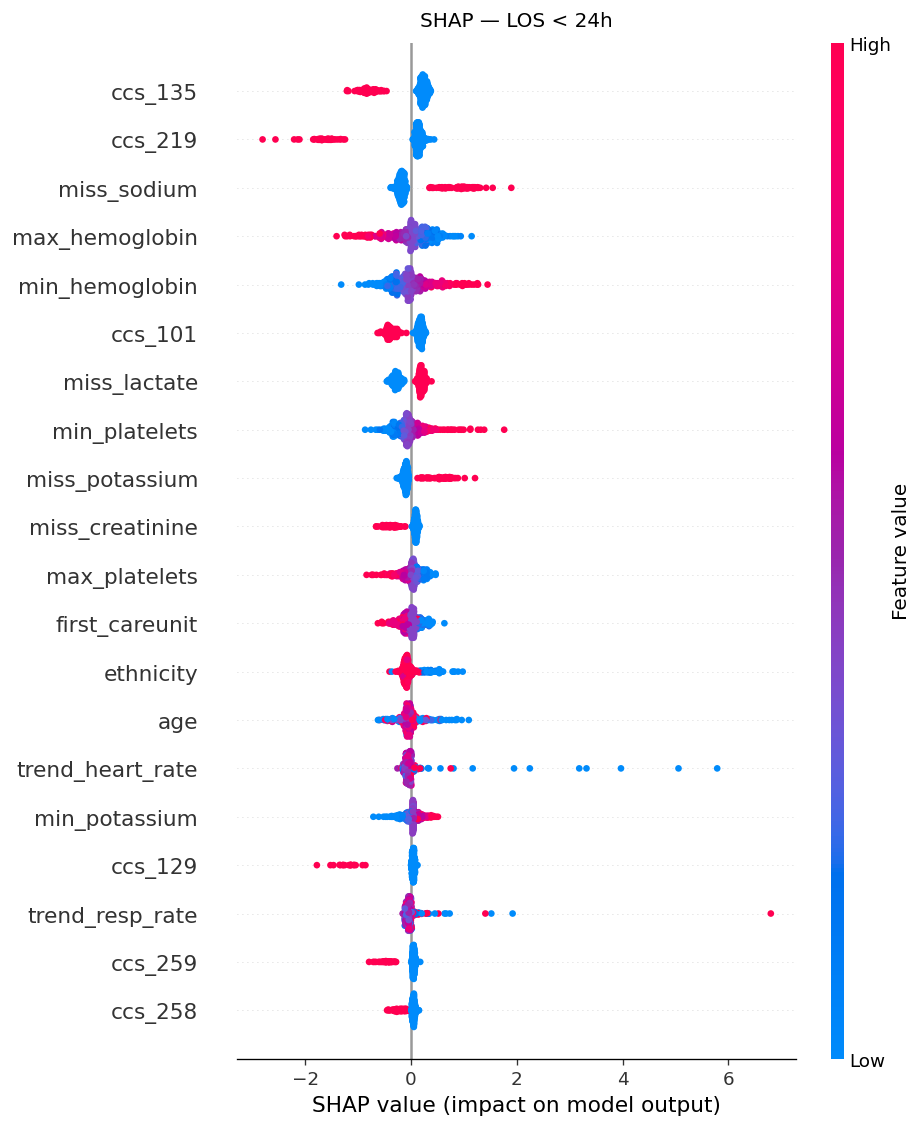

  Saved: /content/drive/MyDrive/MP2/outputs/figures/shap_beeswarm_los_band0.png


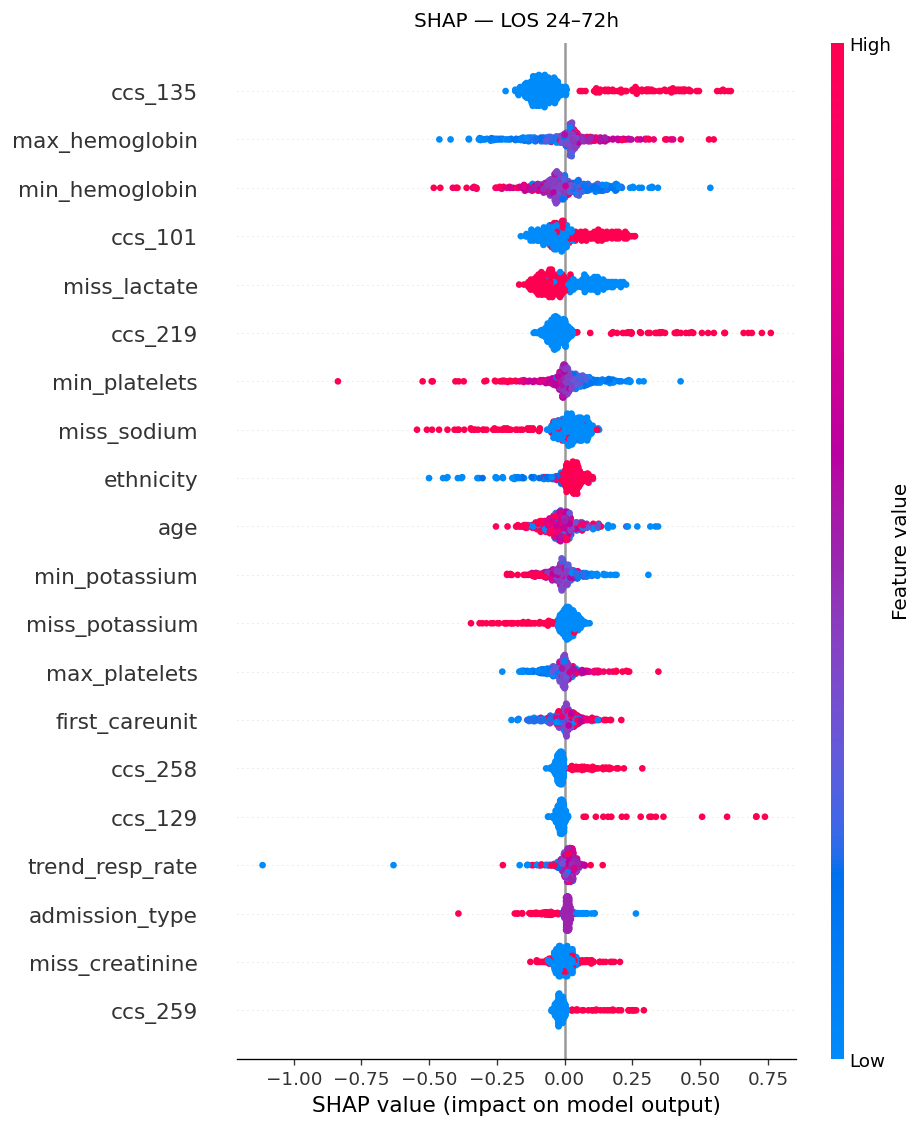

  Saved: /content/drive/MyDrive/MP2/outputs/figures/shap_beeswarm_los_band1.png


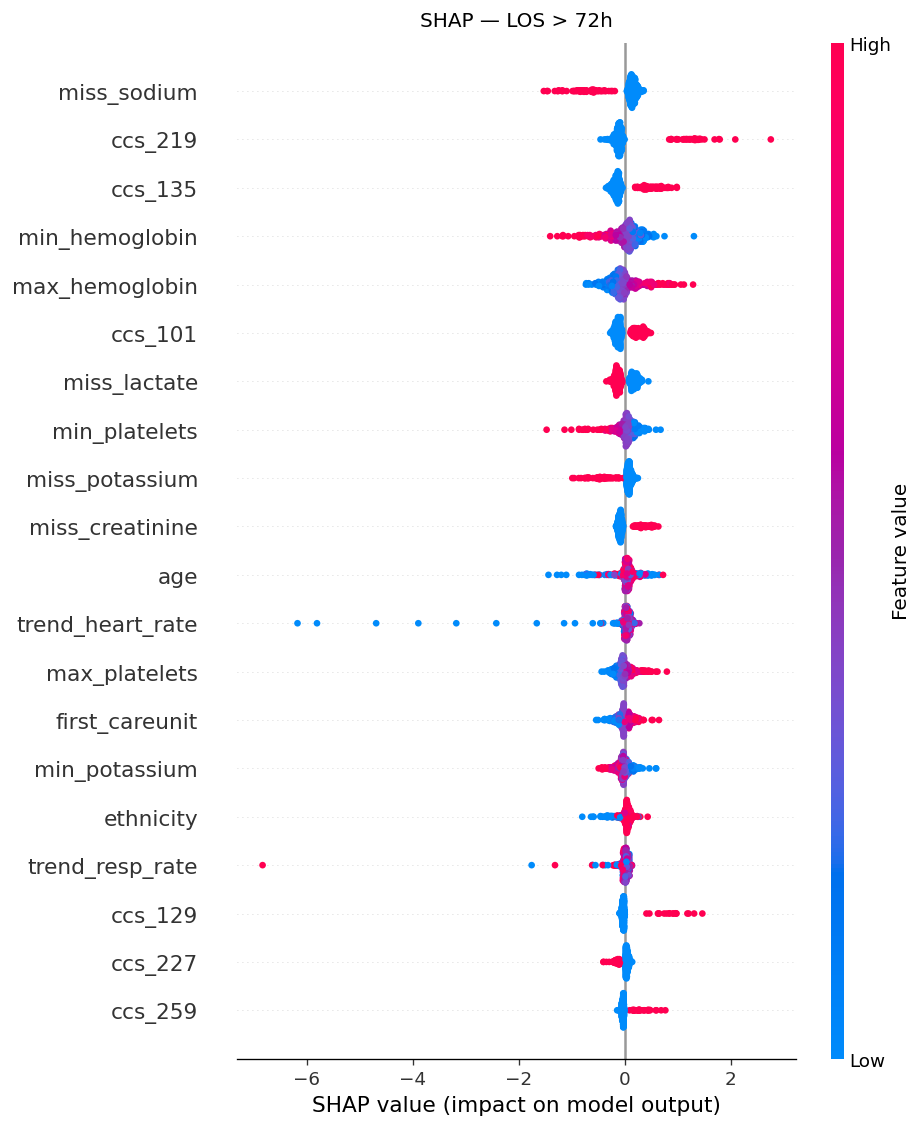

  Saved: /content/drive/MyDrive/MP2/outputs/figures/shap_beeswarm_los_band2.png


In [ ]:
# %% CELL 10 — SHAP beeswarm plots: all three LOS bands
# -----------------------------------------------------------------------------

_band_configs = [
    ("Band0", shap_band0, "LOS < 24h",   "#4CAF50"),
    ("Band1", shap_band1, "LOS 24–72h",  "#FF9800"),
    ("Band2", shap_band2, "LOS > 72h",   "#2196F3"),
]

for tag, shap_arr, label, _ in _band_configs:
    shap.summary_plot(
        shap_arr,
        X_np_shap,
        feature_names=all_feature_names,
        max_display=20,
        show=False,
        plot_type="dot",
    )
    plt.title(f"SHAP — {label}", fontsize=12, pad=10)
    plt.tight_layout()
    fpath = f"{FIG_DIR}/shap_beeswarm_los_{tag.lower()}.png"
    plt.savefig(fpath, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  Saved: {fpath}")

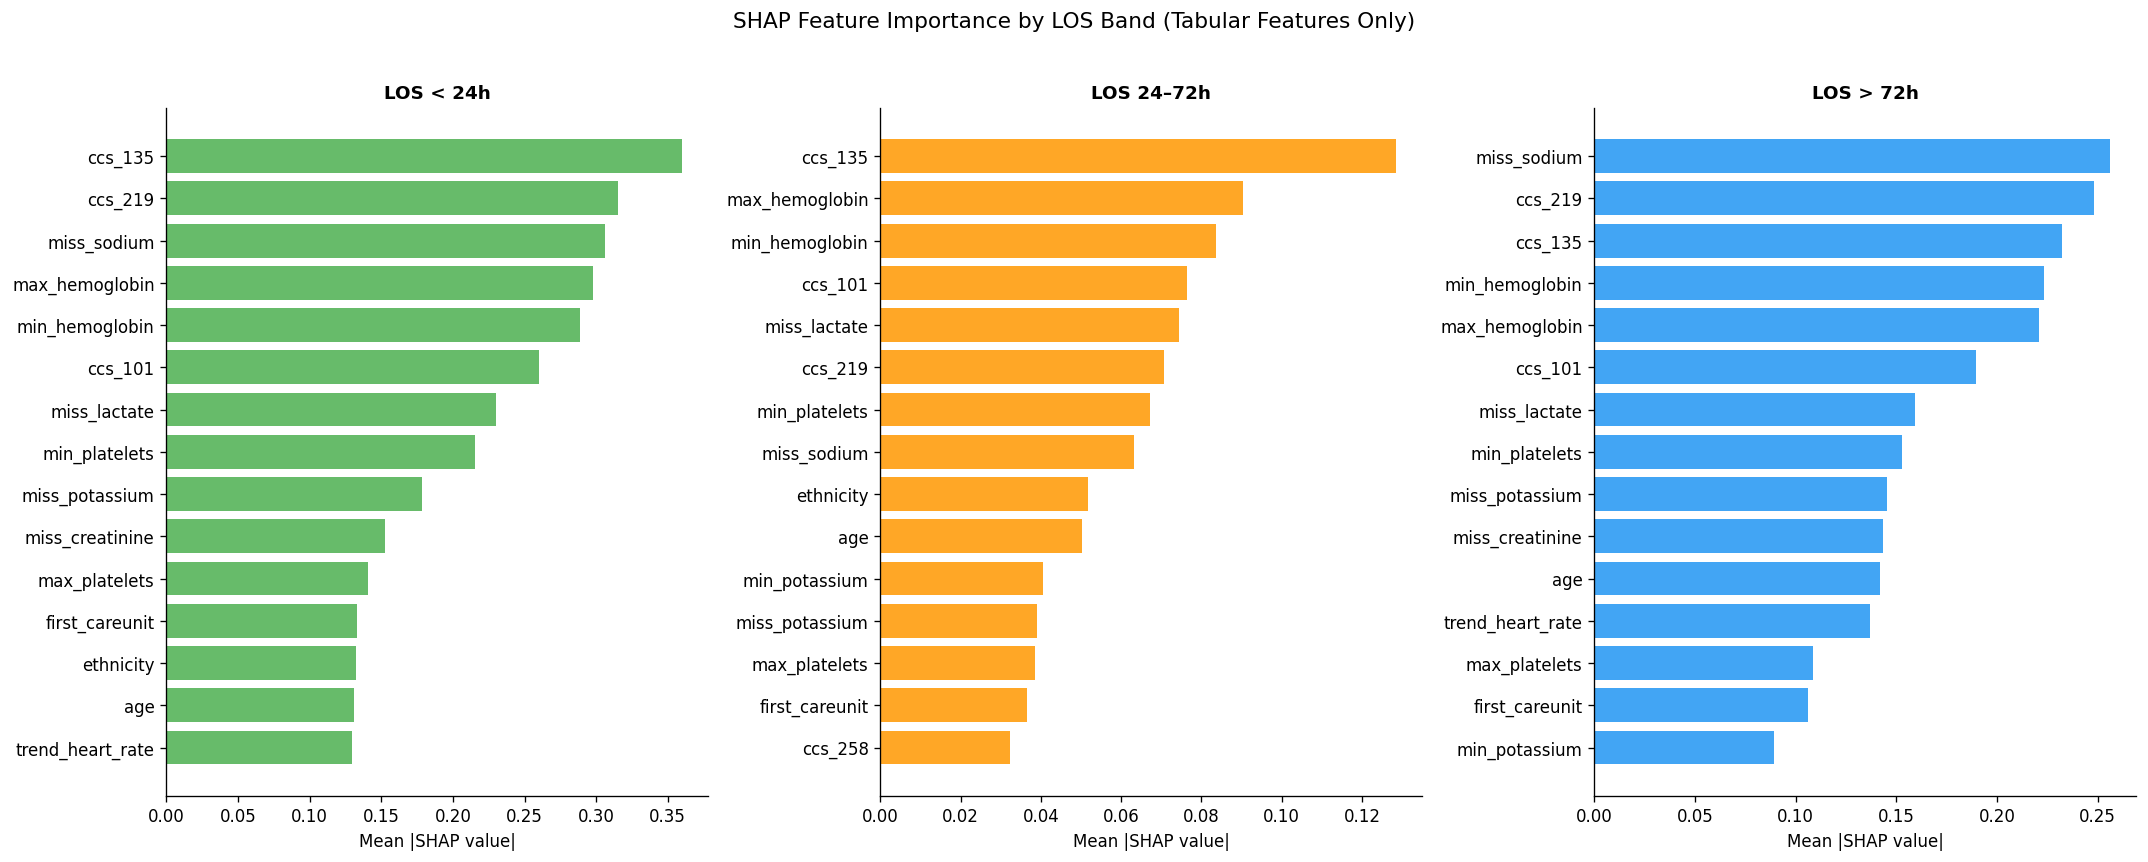

Saved: /content/drive/MyDrive/MP2/outputs/figures/shap_bar_los_bands.png


In [ ]:
# %% CELL 11 — SHAP bar charts: top-15 tabular features per LOS band (side-by-side)
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (tag, shap_arr, label, color) in zip(axes, _band_configs):
    tab_shap = shap_arr[:, VITALS_DIM:]                            # (N, 156) tabular only
    mean_abs = np.abs(tab_shap).mean(axis=0)                       # (156,)
    top_idx  = np.argsort(mean_abs)[::-1][:15]

    ax.barh(
        [feature_names_tabular[i] for i in top_idx[::-1]],
        mean_abs[top_idx[::-1]],
        color=color, alpha=0.85,
    )
    ax.set_xlabel("Mean |SHAP value|")
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "SHAP Feature Importance by LOS Band (Tabular Features Only)",
    fontsize=13, y=1.02,
)
plt.tight_layout()
fpath = f"{FIG_DIR}/shap_bar_los_bands.png"
plt.savefig(fpath, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fpath}")

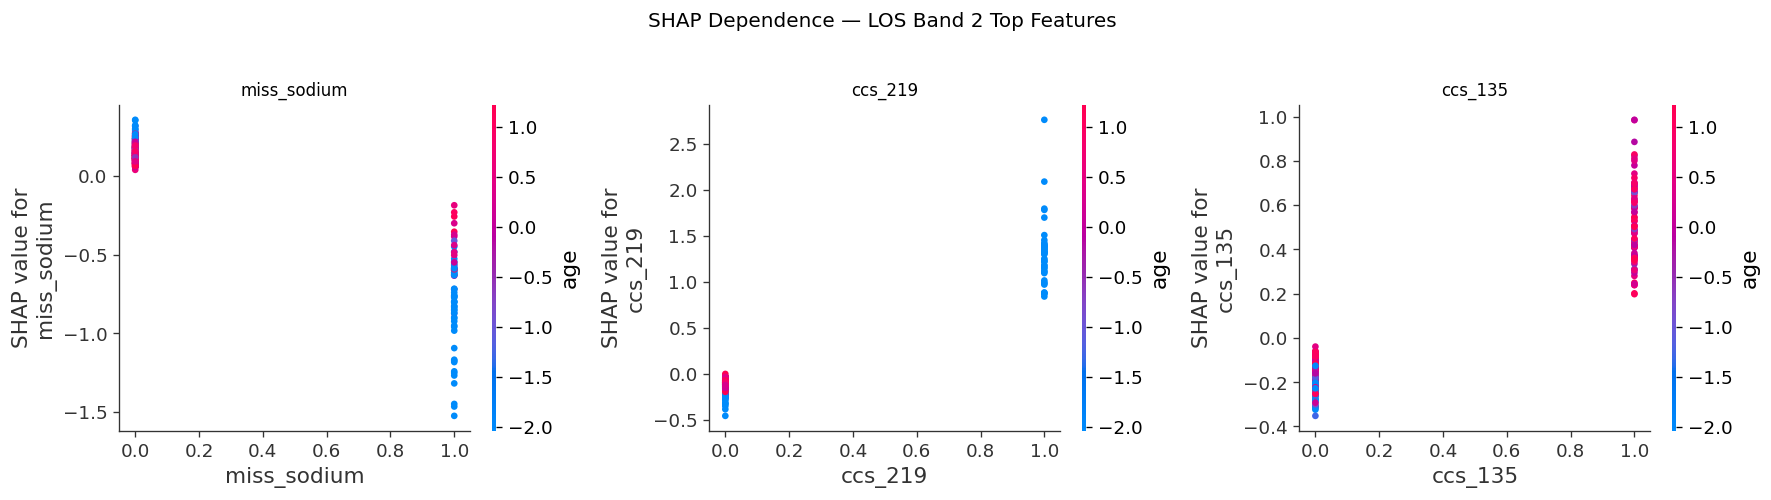

Saved: /content/drive/MyDrive/MP2/outputs/figures/shap_dependence_los_band2.png


In [ ]:
# %% CELL 12 — SHAP dependence plots: top-3 Band 2 tabular features
# -----------------------------------------------------------------------------

tab_shap_b2   = shap_band2[:, VITALS_DIM:]
top3_b2_tidx  = np.argsort(np.abs(tab_shap_b2).mean(axis=0))[::-1][:3]
top3_b2_fidx  = top3_b2_tidx + VITALS_DIM     # offset into the 276-dim space

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (tab_i, feat_i) in zip(axes, zip(top3_b2_tidx, top3_b2_fidx)):
    shap.dependence_plot(
        feat_i,
        shap_band2,
        X_np_shap,
        feature_names=all_feature_names,
        ax=ax,
        show=False,
    )
    ax.set_title(feature_names_tabular[tab_i], fontsize=10)

plt.suptitle("SHAP Dependence — LOS Band 2 Top Features", fontsize=12, y=1.03)
plt.tight_layout()
fpath = f"{FIG_DIR}/shap_dependence_los_band2.png"
plt.savefig(fpath, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fpath}")

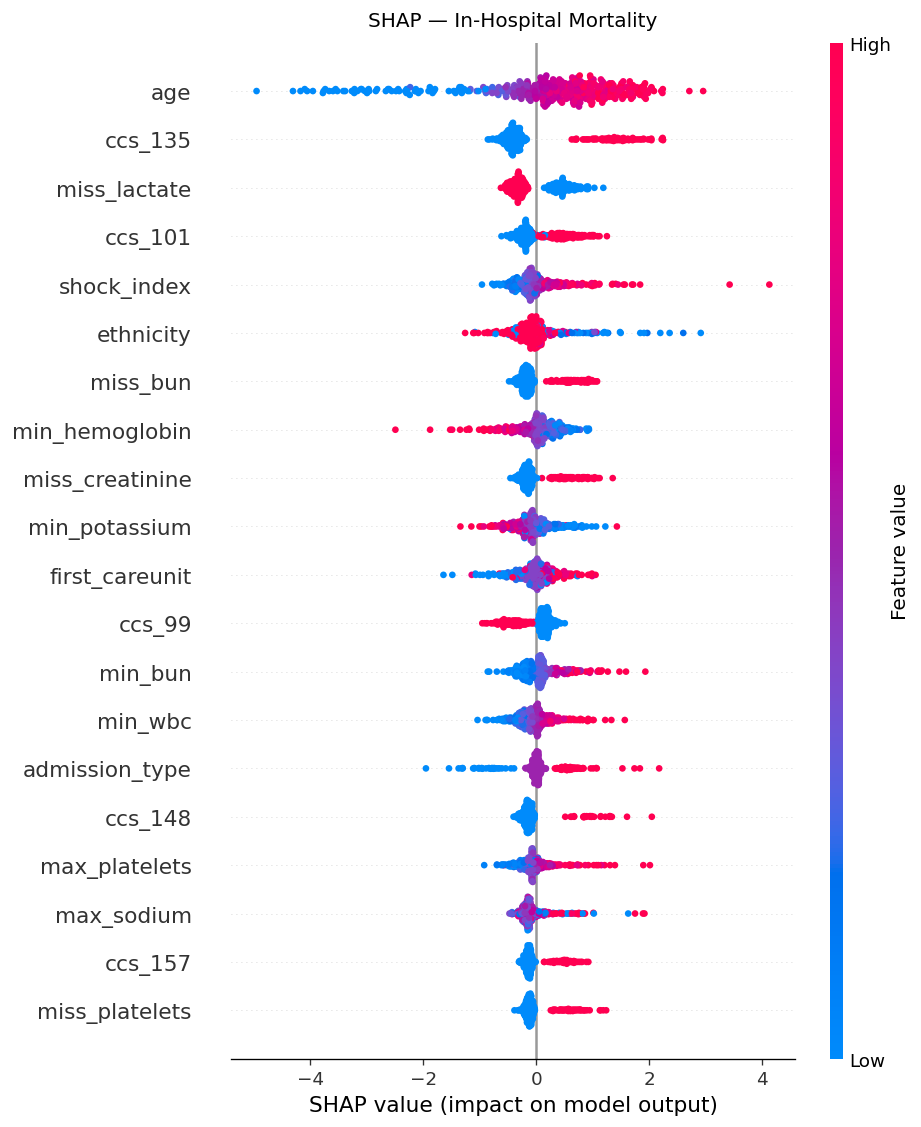

Saved: /content/drive/MyDrive/MP2/outputs/figures/shap_beeswarm_mortality.png


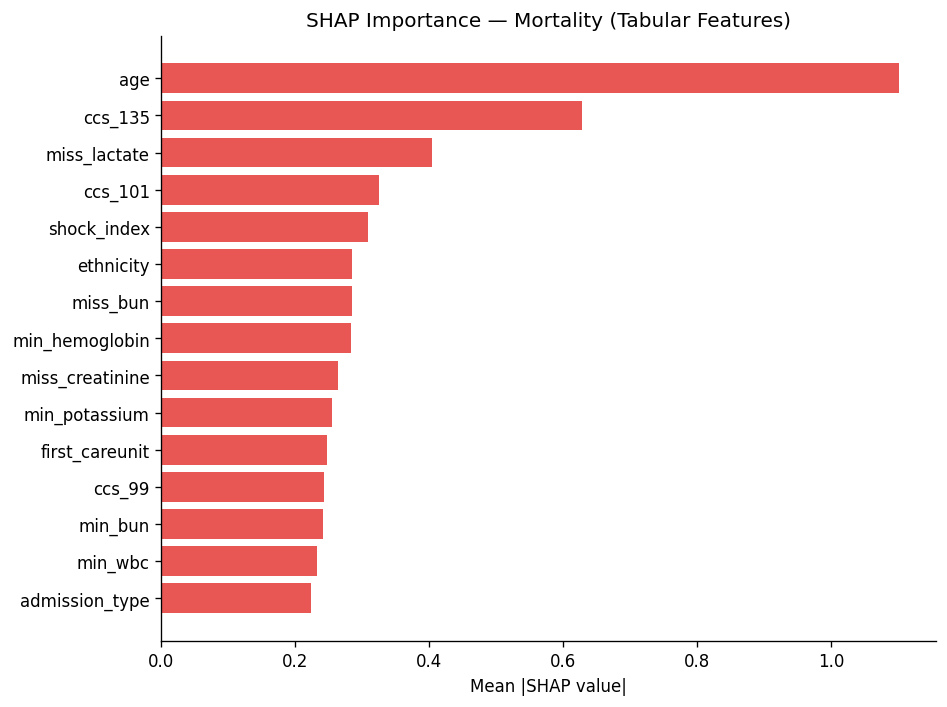

Saved: /content/drive/MyDrive/MP2/outputs/figures/shap_bar_mortality.png


In [ ]:
# %% CELL 13 — Mortality SHAP beeswarm + tabular bar chart
# -----------------------------------------------------------------------------

shap.summary_plot(
    shap_mort, X_np_shap,
    feature_names=all_feature_names,
    max_display=20, show=False, plot_type="dot",
)
plt.title("SHAP — In-Hospital Mortality", fontsize=12, pad=10)
plt.tight_layout()
fpath = f"{FIG_DIR}/shap_beeswarm_mortality.png"
plt.savefig(fpath, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fpath}")

tab_shap_mort = shap_mort[:, VITALS_DIM:]
mean_abs_mort = np.abs(tab_shap_mort).mean(axis=0)
top_idx_mort  = np.argsort(mean_abs_mort)[::-1][:15]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    [feature_names_tabular[i] for i in top_idx_mort[::-1]],
    mean_abs_mort[top_idx_mort[::-1]],
    color="#E53935", alpha=0.85,
)
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("SHAP Importance — Mortality (Tabular Features)", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fpath = f"{FIG_DIR}/shap_bar_mortality.png"
plt.savefig(fpath, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fpath}")

In [ ]:
# %% CELL 14 — LIME explainer setup
# -----------------------------------------------------------------------------

lime_explainer_los = LimeTabularExplainer(
    training_data=X_train_flat, feature_names=all_feature_names,
    class_names=["Band0 <24h", "Band1 24-72h", "Band2 >72h"],
    mode="classification", discretize_continuous=True, random_state=42,
)

lime_explainer_mort = LimeTabularExplainer(
    training_data=X_train_flat, feature_names=all_feature_names,
    class_names=["Survived", "Died"],
    mode="classification", discretize_continuous=True, random_state=42,
)

print("✓ LIME explainers initialised (LOS + Mortality)")

✓ LIME explainers initialised (LOS + Mortality)


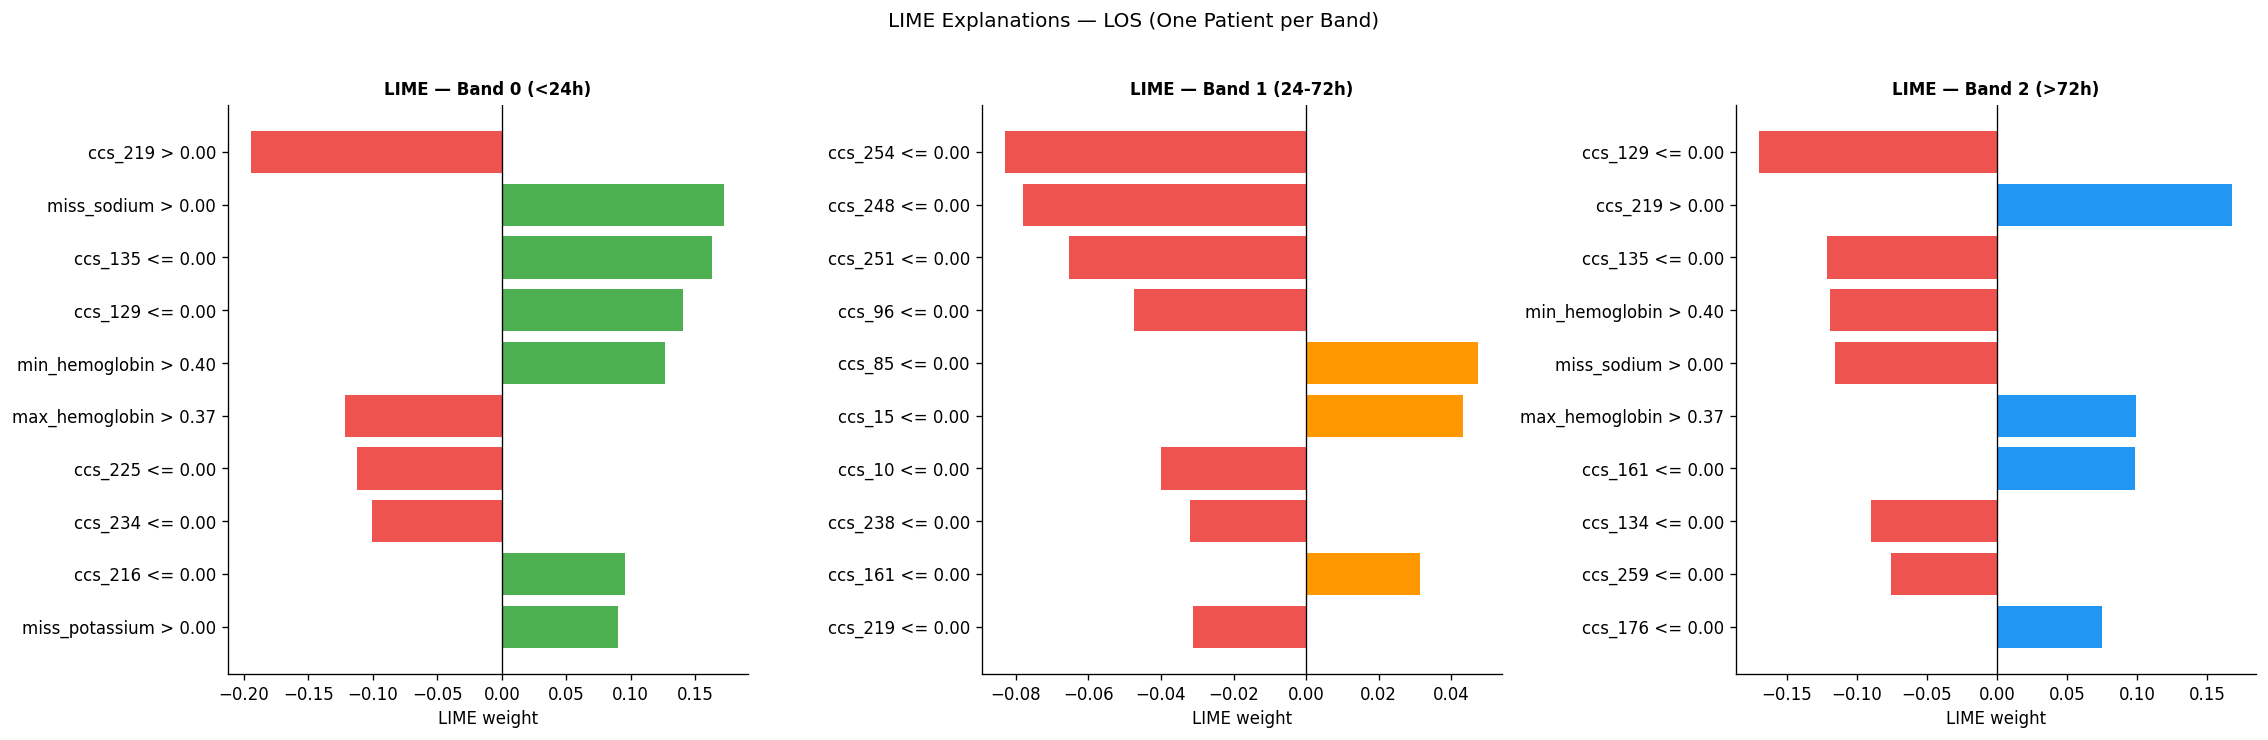

Saved: /content/drive/MyDrive/MP2/outputs/figures/lime_los_per_band.png
  Saved HTML: /content/drive/MyDrive/MP2/outputs/figures/lime_los_band0_patient.html
  Saved HTML: /content/drive/MyDrive/MP2/outputs/figures/lime_los_band1_patient.html
  Saved HTML: /content/drive/MyDrive/MP2/outputs/figures/lime_los_band2_patient.html


In [ ]:
# %% CELL 15 — Patient-level LIME: one example per LOS band
# -----------------------------------------------------------------------------

def _lime_bar(ax, feat_weights, title, pos_color="#2196F3", neg_color="#EF5350"):
    top10   = sorted(feat_weights, key=lambda x: abs(x[1]), reverse=True)[:10]
    feats   = [fw[0][:40] for fw in top10]
    weights = [fw[1] for fw in top10]
    colors  = [pos_color if w > 0 else neg_color for w in weights]
    ax.barh(feats[::-1], weights[::-1], color=colors[::-1])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xlabel("LIME weight")
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 3, figsize=(19, 6))
_band_info = {0: ("Band 0 (<24h)", "#4CAF50"),
              1: ("Band 1 (24-72h)", "#FF9800"),
              2: ("Band 2 (>72h)", "#2196F3")}

for ax, band in zip(axes, [0, 1, 2]):
    idx   = int(np.where(los_test == band)[0][0])
    flat  = X_test_flat[idx]
    label, pos_col = _band_info[band]
    exp = lime_explainer_los.explain_instance(
        flat, predict_fn_los, num_features=15, num_samples=2000, labels=[band],
    )
    _lime_bar(ax, exp.as_list(label=band), title=f"LIME — {label}", pos_color=pos_col)

plt.suptitle("LIME Explanations — LOS (One Patient per Band)", fontsize=12, y=1.02)
plt.tight_layout()
fpath = f"{FIG_DIR}/lime_los_per_band.png"
plt.savefig(fpath, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fpath}")

for band in [0, 1, 2]:
    idx = int(np.where(los_test == band)[0][0])
    exp = lime_explainer_los.explain_instance(
        X_test_flat[idx], predict_fn_los, num_features=15, num_samples=2000, labels=[band],
    )
    html_path = f"{FIG_DIR}/lime_los_band{band}_patient.html"
    with open(html_path, "w") as fh:
        fh.write(exp.as_html())
    print(f"  Saved HTML: {html_path}")

Aggregating LIME — Band 2 (20 patients) …

Aggregating LIME — Band 1 (20 patients) …

Aggregating LIME — Band 0 (20 patients) …



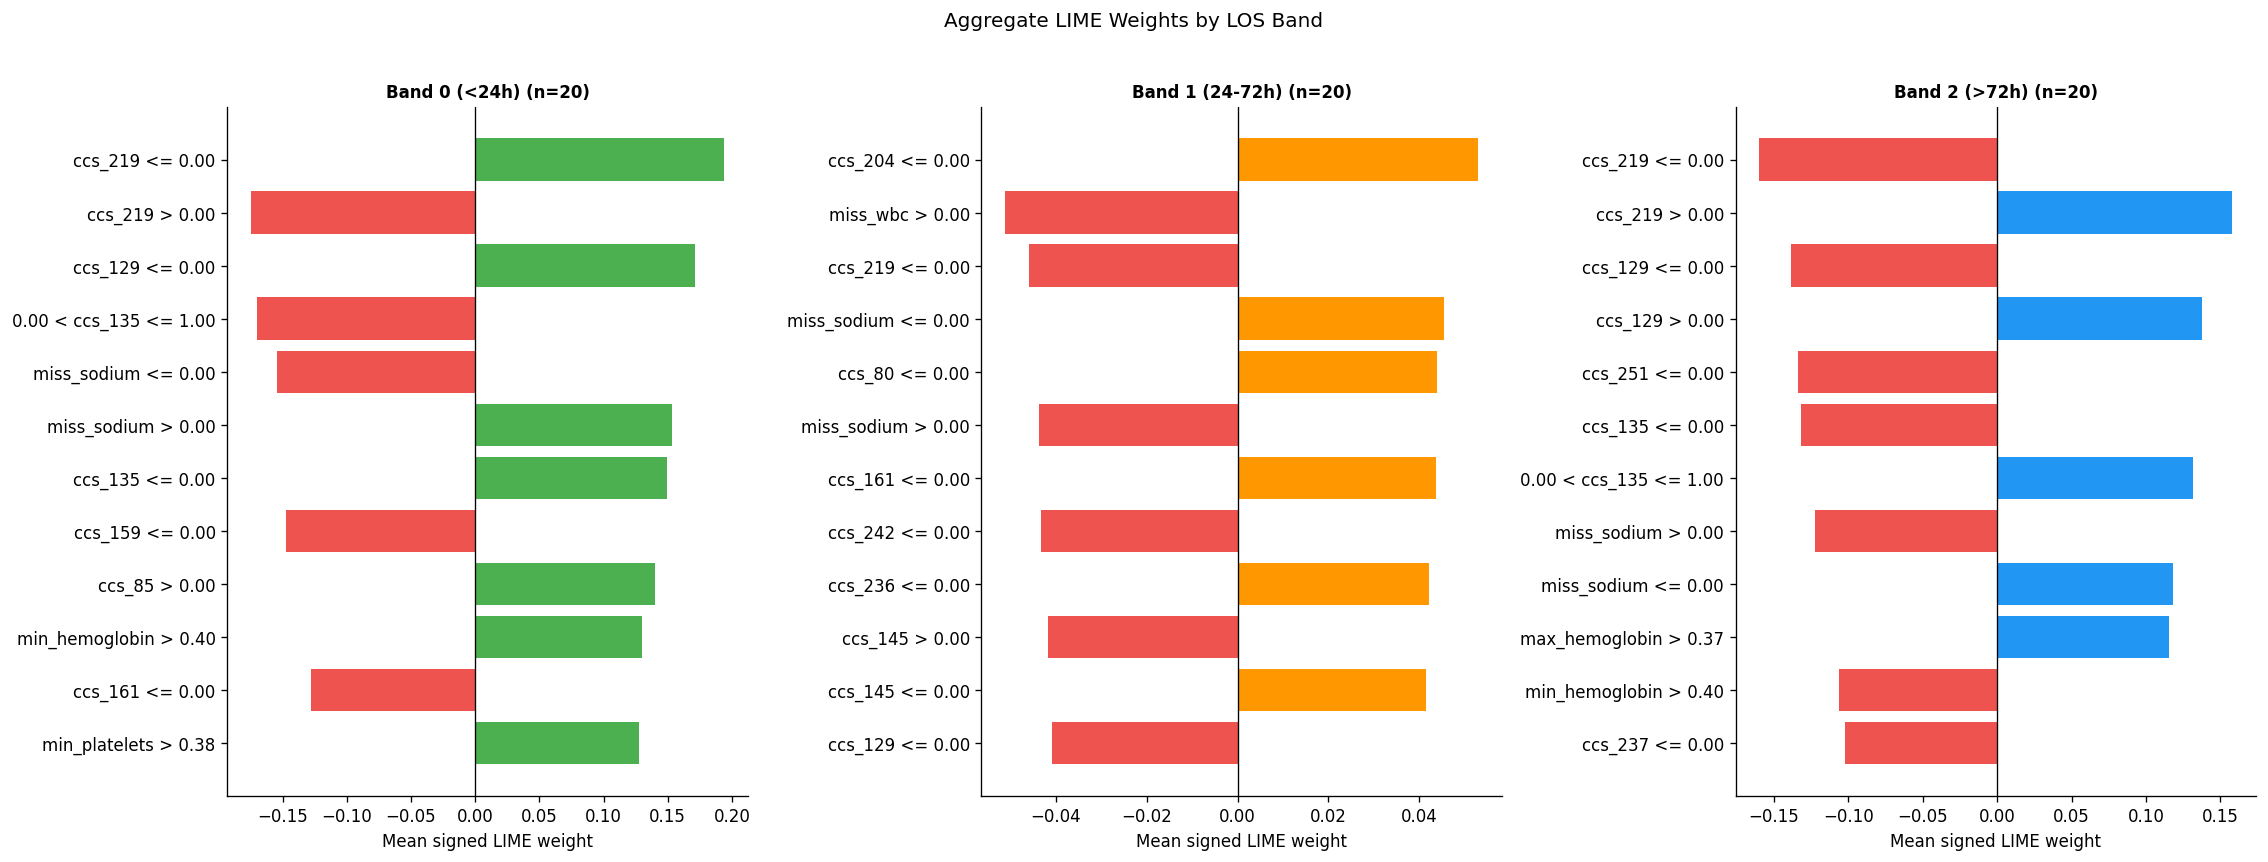

Saved: /content/drive/MyDrive/MP2/outputs/figures/lime_aggregate_los_bands.png


In [ ]:
# %% CELL 16 — Aggregate LIME: stratified groups for all LOS bands
# -----------------------------------------------------------------------------

def aggregate_lime_weights(indices, predict_fn, explainer, target_class,
                            num_features=15, num_samples=1000):
    accumulator = {}
    n = len(indices)
    for i, idx in enumerate(indices):
        print(f"  {i+1}/{n}", end="\r")
        exp = explainer.explain_instance(
            X_test_flat[idx], predict_fn,
            num_features=num_features, num_samples=num_samples, labels=[target_class],
        )
        for feat, w in exp.as_list(label=target_class):
            accumulator.setdefault(feat, []).append(w)
    print()
    return {k: float(np.mean(v)) for k, v in accumulator.items()}


band2_idx = np.where(los_test == 2)[0][:20]
band1_idx = np.where(los_test == 1)[0][:20]
band0_idx = np.where(los_test == 0)[0][:20]

print("Aggregating LIME — Band 2 (20 patients) …")
agg_band2_lime = aggregate_lime_weights(band2_idx, predict_fn_los, lime_explainer_los, 2)
print("Aggregating LIME — Band 1 (20 patients) …")
agg_band1_lime = aggregate_lime_weights(band1_idx, predict_fn_los, lime_explainer_los, 1)
print("Aggregating LIME — Band 0 (20 patients) …")
agg_band0_lime = aggregate_lime_weights(band0_idx, predict_fn_los, lime_explainer_los, 0)

fig, axes = plt.subplots(1, 3, figsize=(19, 7))
for ax, (agg_d, label, pos_col) in zip(axes, [
    (agg_band0_lime, "Band 0 (<24h)",   "#4CAF50"),
    (agg_band1_lime, "Band 1 (24-72h)", "#FF9800"),
    (agg_band2_lime, "Band 2 (>72h)",   "#2196F3"),
]):
    top_items = sorted(agg_d.items(), key=lambda x: abs(x[1]), reverse=True)[:12]
    feats   = [it[0][:40] for it in top_items]
    weights = [it[1] for it in top_items]
    colors  = [pos_col if w > 0 else "#EF5350" for w in weights]
    ax.barh(feats[::-1], weights[::-1], color=colors[::-1])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{label} (n=20)", fontsize=10, fontweight="bold")
    ax.set_xlabel("Mean signed LIME weight")
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Aggregate LIME Weights by LOS Band", fontsize=12, y=1.02)
plt.tight_layout()
fpath = f"{FIG_DIR}/lime_aggregate_los_bands.png"
plt.savefig(fpath, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fpath}")

  Saved HTML: /content/drive/MyDrive/MP2/outputs/figures/lime_mort_survivor.html
  Saved HTML: /content/drive/MyDrive/MP2/outputs/figures/lime_mort_nonsurvivor.html


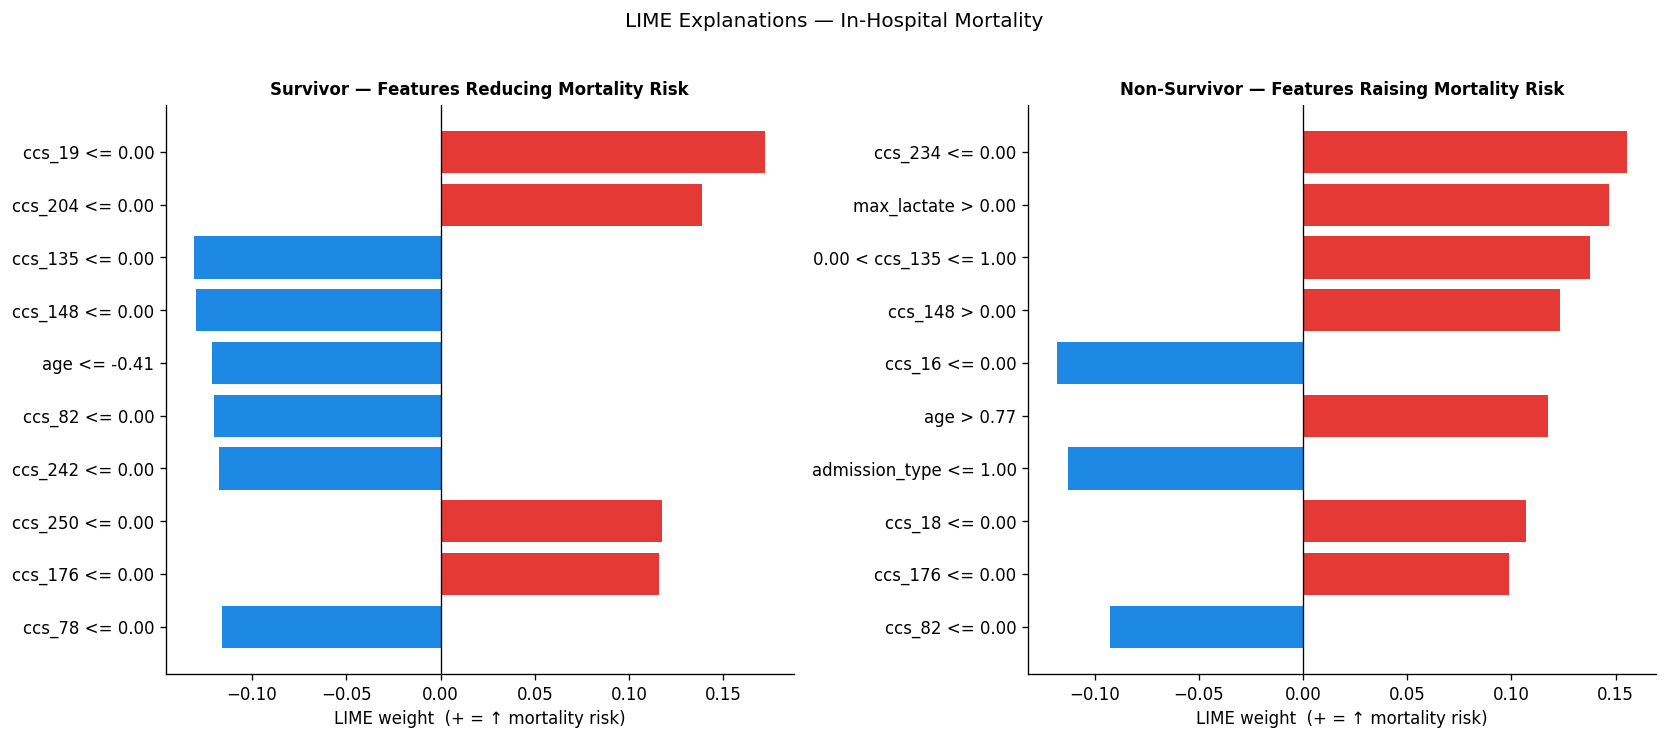

Saved: /content/drive/MyDrive/MP2/outputs/figures/lime_mortality_patients.png
Aggregating LIME — Mortality non-survivors (20 patients) …



In [ ]:
# %% CELL 17 — Patient-level LIME: Mortality
# -----------------------------------------------------------------------------

surv_idx  = int(np.where(mort_test == 0)[0][0])
death_idx = int(np.where(mort_test == 1)[0][0])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (idx, title) in zip(axes, [
    (surv_idx,  "Survivor — Features Reducing Mortality Risk"),
    (death_idx, "Non-Survivor — Features Raising Mortality Risk"),
]):
    exp = lime_explainer_mort.explain_instance(
        X_test_flat[idx], predict_fn_mort,
        num_features=15, num_samples=2000, labels=[1],
    )
    _lime_bar(ax, exp.as_list(label=1), title=title,
              pos_color="#E53935", neg_color="#1E88E5")
    ax.set_xlabel("LIME weight  (+ = ↑ mortality risk)")
    html_path = f"{FIG_DIR}/lime_mort_{'nonsurvivor' if idx==death_idx else 'survivor'}.html"
    with open(html_path, "w") as fh:
        fh.write(exp.as_html())
    print(f"  Saved HTML: {html_path}")

plt.suptitle("LIME Explanations — In-Hospital Mortality", fontsize=12, y=1.02)
plt.tight_layout()
fpath = f"{FIG_DIR}/lime_mortality_patients.png"
plt.savefig(fpath, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fpath}")

print("Aggregating LIME — Mortality non-survivors (20 patients) …")
death_20_idx  = np.where(mort_test == 1)[0][:20]
agg_mort_lime = aggregate_lime_weights(
    death_20_idx, predict_fn_mort, lime_explainer_mort, target_class=1
)

In [ ]:
# %% CELL 18 — Signed Spearman correlation: SHAP vs Aggregate LIME
# -----------------------------------------------------------------------------

def _lime_to_tabular_vec(lime_agg_dict, feature_names_tabular):
    vec = np.zeros(len(feature_names_tabular))
    for lime_key, lime_val in lime_agg_dict.items():
        for i, fname in enumerate(feature_names_tabular):
            if fname in lime_key:
                vec[i] += lime_val
                break
    return vec


def signed_spearman_shap_lime(shap_tab_arr, lime_agg_dict, feature_names_tabular):
    shap_mean = shap_tab_arr.mean(axis=0)
    lime_vec  = _lime_to_tabular_vec(lime_agg_dict, feature_names_tabular)
    active    = (np.abs(shap_mean) > 0) | (np.abs(lime_vec) > 0)
    if active.sum() < 10:
        print("  Warning: fewer than 10 active features for comparison")
    rho, pval = spearmanr(shap_mean[active], lime_vec[active])
    return float(rho), float(pval)


# Filter SHAP to band-specific patients only (same population as LIME)
band0_mask = (los_test_shap == 0)
band1_mask = (los_test_shap == 1)
band2_mask = (los_test_shap == 2)

rho_b0, p_b0 = signed_spearman_shap_lime(
    shap_band0[band0_mask, VITALS_DIM:], agg_band0_lime, feature_names_tabular)
rho_b1, p_b1 = signed_spearman_shap_lime(
    shap_band1[band1_mask, VITALS_DIM:], agg_band1_lime, feature_names_tabular)
rho_b2, p_b2 = signed_spearman_shap_lime(
    shap_band2[band2_mask, VITALS_DIM:], agg_band2_lime, feature_names_tabular)
rho_mt, p_mt = signed_spearman_shap_lime(
    shap_mort[:, VITALS_DIM:], agg_mort_lime, feature_names_tabular)

print("=" * 58)
print("  SHAP–LIME Signed Spearman Consistency")
print("=" * 58)
print(f"  Band 0 (<24h)     ρ = {rho_b0:+.3f}   p = {p_b0:.4f}")
print(f"  Band 1 (24-72h)   ρ = {rho_b1:+.3f}   p = {p_b1:.4f}")
print(f"  Band 2 (>72h)     ρ = {rho_b2:+.3f}   p = {p_b2:.4f}")
print(f"  Mortality         ρ = {rho_mt:+.3f}   p = {p_mt:.4f}")
print("=" * 58)
print("  ρ > 0.60 = strong    0.30–0.60 = moderate    < 0.30 = weak")
print()
print("  NOTE: LIME uses 20 patients; SHAP uses ~133.  Some divergence is")
print("  expected on Band 1 (the persistently hard class).  Low Band 1 ρ is")
print("  informative: the two methods disagree on which features drive the")
print("  24–72h classification, reflecting genuine model ambiguity there.")

  SHAP–LIME Signed Spearman Consistency
  Band 0 (<24h)     ρ = +0.172   p = 0.0325
  Band 1 (24-72h)   ρ = +0.163   p = 0.0425
  Band 2 (>72h)     ρ = -0.127   p = 0.1165
  Mortality         ρ = +0.009   p = 0.9068
  ρ > 0.60 = strong    0.30–0.60 = moderate    < 0.30 = weak

  NOTE: LIME uses 20 patients; SHAP uses ~133.  Some divergence is
  expected on Band 1 (the persistently hard class).  Low Band 1 ρ is
  informative: the two methods disagree on which features drive the
  24–72h classification, reflecting genuine model ambiguity there.


In [ ]:
# %% CELL 19 — Disagreement case analysis: SHAP vs LIME top-5 features
# -----------------------------------------------------------------------------

def _shap_top_tabular(shap_row_276, k=5):
    return set(map(int, np.argsort(np.abs(shap_row_276[VITALS_DIM:]))[::-1][:k]))

def _lime_top_tabular(flat_instance, predict_fn, explainer, target_class, k=5):
    exp = explainer.explain_instance(
        flat_instance, predict_fn,
        num_features=20, num_samples=500, labels=[target_class],
    )
    ranked  = sorted(exp.as_list(label=target_class), key=lambda x: abs(x[1]), reverse=True)
    matched = set()
    for lime_key, _ in ranked:
        if len(matched) >= k:
            break
        for i, fname in enumerate(feature_names_tabular):
            if fname in lime_key:
                matched.add(i)
                break
    return matched


print("Checking SHAP–LIME agreement on 40 Band-2 test patients …")
b2_check_idx  = np.where(los_test == 2)[0][:40]
disagreements = []

for i, idx in enumerate(b2_check_idx):
    print(f"  {i+1}/40", end="\r")
    flat_t   = torch.tensor(X_test_flat[[idx]], dtype=torch.float32)
    sv       = shap_explainer_los.shap_values(flat_t)
    shap_top = _shap_top_tabular(sv[..., 1][0], k=5)   # logit_1 = Band 2 signal
    lime_top = _lime_top_tabular(
        X_test_flat[idx], predict_fn_los, lime_explainer_los, target_class=2, k=5
    )
    overlap = len(shap_top & lime_top)
    if overlap < 3:
        disagreements.append({
            "test_idx"  : int(idx), "overlap": overlap,
            "shap_names": [feature_names_tabular[j] for j in shap_top],
            "lime_names": [feature_names_tabular[j] for j in lime_top],
        })

print(f"\n✓ Disagreement cases (top-5 overlap < 3/5): {len(disagreements)} / 40")
if disagreements:
    print("\nSample disagreements:")
    for d in disagreements[:3]:
        print(f"  Patient {d['test_idx']:5d}  overlap={d['overlap']}/5")
        print(f"    SHAP top-5: {d['shap_names']}")
        print(f"    LIME top-5: {d['lime_names']}")

Checking SHAP–LIME agreement on 40 Band-2 test patients …

✓ Disagreement cases (top-5 overlap < 3/5): 40 / 40

Sample disagreements:
  Patient     3  overlap=1/5
    SHAP top-5: ['miss_creatinine', 'miss_sodium', 'miss_potassium', 'max_hemoglobin', 'ccs_219']
    LIME top-5: ['ccs_129', 'ccs_250', 'min_hemoglobin', 'ccs_254', 'ccs_219']
  Patient     4  overlap=1/5
    SHAP top-5: ['ccs_135', 'ccs_133', 'ccs_8', 'ccs_101', 'max_hemoglobin']
    LIME top-5: ['ccs_129', 'ccs_80', 'ccs_8', 'miss_sodium', 'ccs_219']
  Patient    11  overlap=1/5
    SHAP top-5: ['ccs_135', 'ccs_149', 'min_hemoglobin', 'miss_sodium', 'max_hemoglobin']
    LIME top-5: ['ccs_129', 'ccs_250', 'miss_potassium', 'max_hemoglobin', 'ccs_219']


In [ ]:
# %% CELL 20 — Summary report
# -----------------------------------------------------------------------------

print("\n" + "=" * 65)
print("  EXPLAINABILITY ANALYSIS — FINAL SUMMARY")
print("=" * 65)

print("\n  [SHAP — LOS Top-5 Tabular Features]")
for tag, shap_arr, label, _ in _band_configs:
    tab  = shap_arr[:, VITALS_DIM:]
    top5 = [feature_names_tabular[i]
            for i in np.argsort(np.abs(tab).mean(axis=0))[::-1][:5]]
    print(f"    {label:15s}: {top5}")

print("\n  [SHAP — Mortality Top-5 Tabular Features]")
top5_mort_names = [feature_names_tabular[i]
                   for i in np.argsort(np.abs(shap_mort[:, VITALS_DIM:]).mean(0))[::-1][:5]]
print(f"    Mortality      : {top5_mort_names}")

print("\n  [SHAP–LIME Signed Spearman ρ]")
print(f"    Band 0: {rho_b0:+.3f}  Band 1: {rho_b1:+.3f}  "
      f"Band 2: {rho_b2:+.3f}  Mortality: {rho_mt:+.3f}")

print("\n  [Agreement Check — Band 2]")
print(f"    {len(disagreements)}/40 patients had SHAP–LIME top-5 overlap < 3")

print("\n  [Output Files]")
_expected = [
    "shap_beeswarm_los_band0.png", "shap_beeswarm_los_band1.png",
    "shap_beeswarm_los_band2.png", "shap_bar_los_bands.png",
    "shap_dependence_los_band2.png",
    "shap_beeswarm_mortality.png",  "shap_bar_mortality.png",
    "lime_los_per_band.png",        "lime_aggregate_los_bands.png",
    "lime_mortality_patients.png",
    "lime_los_band0_patient.html",  "lime_los_band1_patient.html",
    "lime_los_band2_patient.html",  "lime_mort_survivor.html",
    "lime_mort_nonsurvivor.html",
]
for f in _expected:
    full_path = f"{FIG_DIR}/{f}"
    status    = "✓" if os.path.exists(full_path) else "✗ MISSING"
    print(f"    {status}  {f}")

print("\n" + "=" * 65)


  EXPLAINABILITY ANALYSIS — FINAL SUMMARY

  [SHAP — LOS Top-5 Tabular Features]
    LOS < 24h      : ['ccs_135', 'ccs_219', 'miss_sodium', 'max_hemoglobin', 'min_hemoglobin']
    LOS 24–72h     : ['ccs_135', 'max_hemoglobin', 'min_hemoglobin', 'ccs_101', 'miss_lactate']
    LOS > 72h      : ['miss_sodium', 'ccs_219', 'ccs_135', 'min_hemoglobin', 'max_hemoglobin']

  [SHAP — Mortality Top-5 Tabular Features]
    Mortality      : ['age', 'ccs_135', 'miss_lactate', 'ccs_101', 'shock_index']

  [SHAP–LIME Signed Spearman ρ]
    Band 0: +0.172  Band 1: +0.163  Band 2: -0.127  Mortality: +0.009

  [Agreement Check — Band 2]
    40/40 patients had SHAP–LIME top-5 overlap < 3

  [Output Files]
    ✓  shap_beeswarm_los_band0.png
    ✓  shap_beeswarm_los_band1.png
    ✓  shap_beeswarm_los_band2.png
    ✓  shap_bar_los_bands.png
    ✓  shap_dependence_los_band2.png
    ✓  shap_beeswarm_mortality.png
    ✓  shap_bar_mortality.png
    ✓  lime_los_per_band.png
    ✓  lime_aggregate_los_bands.png
 